<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula23a_imbalance_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

In [1]:
!unzip archive.zip

unzip:  cannot find or open archive.zip, archive.zip.zip or archive.zip.ZIP.


In [2]:
!rm archive.zip

rm: cannot remove 'archive.zip': No such file or directory


In [3]:
import pandas as pd

df = pd.read_csv('creditcard.csv')

print("Number of instances per class:")
print(df['Class'].value_counts())

Number of instances per class:
Class
0    284315
1       492
Name: count, dtype: int64


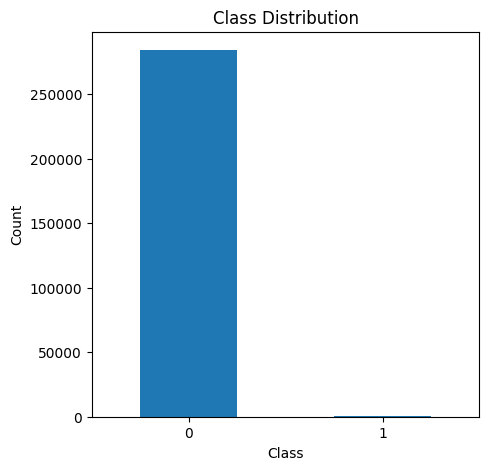

In [4]:
from matplotlib import pyplot as plt

class_counts = df['Class'].value_counts()
plt.figure(figsize=(5,5))
class_counts.plot(kind='bar')
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Class Distribution')
plt.xticks(rotation=0)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    stratify=y,
                                                    test_size=0.2,
                                                    random_state=42)
print("Number of instances in training set:")
print(y_train.value_counts())
print("Number of instances in test set:")
print(y_test.value_counts())

Number of instances in training set:
Class
0    227451
1       394
Name: count, dtype: int64
Number of instances in test set:
Class
0    56864
1       98
Name: count, dtype: int64


In [6]:
from sklearn.dummy import DummyClassifier

model = DummyClassifier(strategy='most_frequent')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Accuracy of dummy classifier: {model.score(X_test, y_test)}")

Accuracy of dummy classifier: 0.9982795547909132


In [7]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[56864     0]
 [   98     0]]


In [8]:
import warnings
warnings.filterwarnings('ignore')

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, tol=1e-3)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Accuracy of logistic regression: {model.score(X_test, y_test)}")

Accuracy of logistic regression: 0.9992099996488887


In [10]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[56849    15]
 [   30    68]]


In [11]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.69      0.75        98

    accuracy                           1.00     56962
   macro avg       0.91      0.85      0.88     56962
weighted avg       1.00      1.00      1.00     56962



In [12]:
y_prob = model.predict_proba(X_test)[:, 1]
threshold = 0.4
y_pred = (y_prob > threshold).astype(int)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[56849    15]
 [   28    70]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.71      0.77        98

    accuracy                           1.00     56962
   macro avg       0.91      0.86      0.88     56962
weighted avg       1.00      1.00      1.00     56962



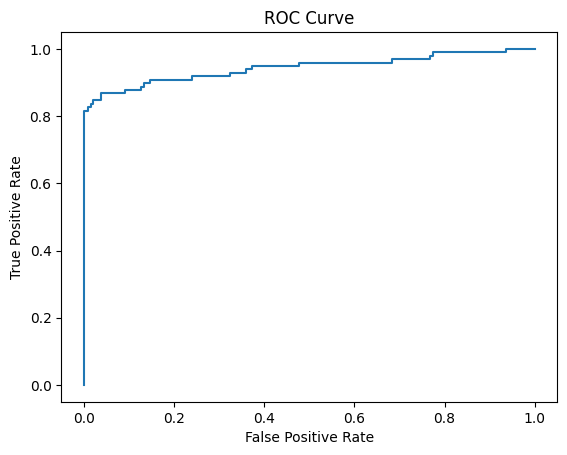

In [13]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [14]:
print(f"AUC: {roc_auc_score(y_test, y_prob)}")

AUC: 0.9431563530026529


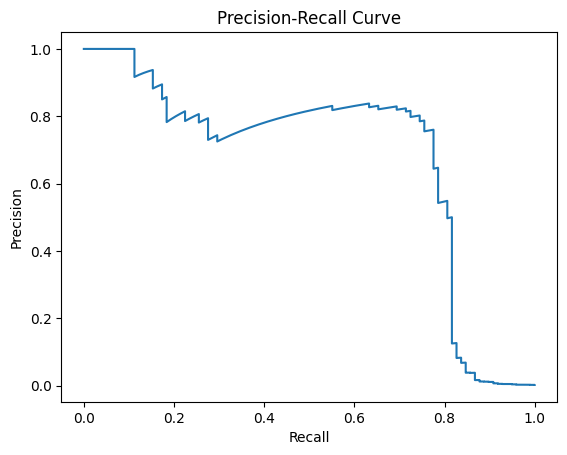

In [15]:
from sklearn.metrics import precision_recall_curve, auc

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

In [16]:
print(f"AUC: {auc(recall, precision)}")

AUC: 0.6760254485788029


In [17]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)
print("Number of instances per class:")
print(y_resampled.value_counts())

Number of instances per class:
Class
0    284315
1    284315
Name: count, dtype: int64


Confusion matrix:
[[55157  1707]
 [    8    90]]
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.92      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962

PR AUC: 0.7379851995607628


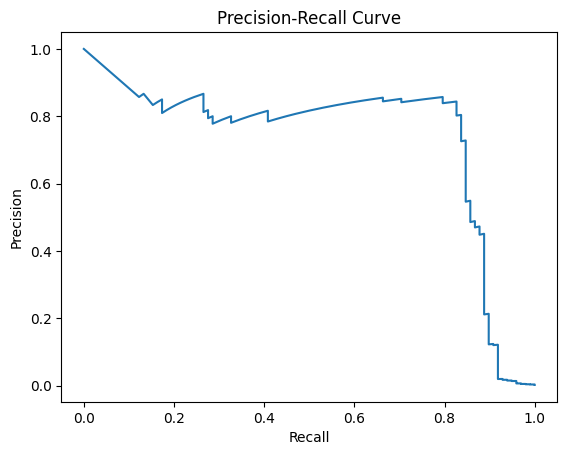

In [18]:
def perform_experiment():
  model.fit(X_resampled, y_resampled)
  y_pred = model.predict(X_test)
  print(f"Confusion matrix:\n{confusion_matrix(y_test, y_pred)}")
  print(f"Classification report:\n{classification_report(y_test, y_pred)}")
  y_prob = model.predict_proba(X_test)[:, 1]
  precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
  pr_auc = auc(recall, precision)
  print(f"PR AUC: {pr_auc}")
  plt.plot(recall, precision)
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.title('Precision-Recall Curve')
  plt.show()
perform_experiment()

In [19]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_resampled, y_resampled = rus.fit_resample(X, y)
print("Number of instances per class:")
print(y_resampled.value_counts())

Number of instances per class:
Class
0    492
1    492
Name: count, dtype: int64


Confusion matrix:
[[54985  1879]
 [    8    90]]
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.92      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962

PR AUC: 0.7035467103230088


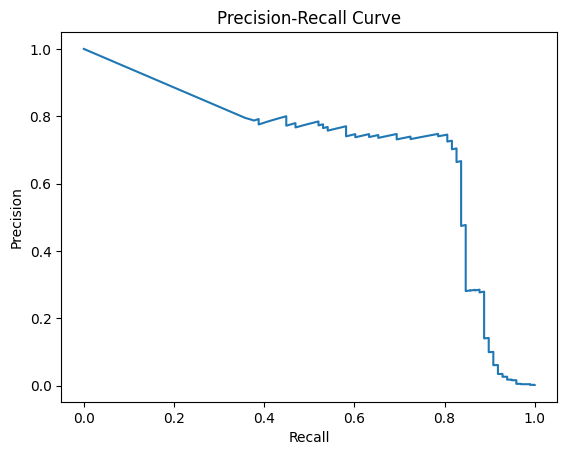

In [20]:
perform_experiment()

In [21]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)
print("Number of instances per class:")
print(y_resampled.value_counts())

Number of instances per class:
Class
0    284315
1    284315
Name: count, dtype: int64


Confusion matrix:
[[56212   652]
 [    9    89]]
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.91      0.21        98

    accuracy                           0.99     56962
   macro avg       0.56      0.95      0.60     56962
weighted avg       1.00      0.99      0.99     56962

PR AUC: 0.7863427956089952


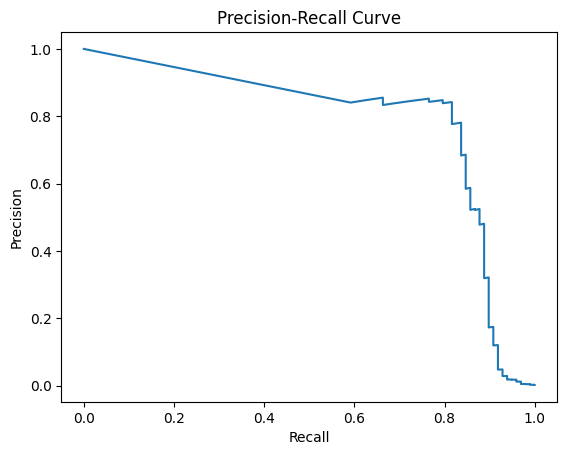

In [22]:
perform_experiment()

In [23]:
from imblearn.under_sampling import NearMiss

X_resampled, y_resampled = NearMiss().fit_resample(X, y)
print("Number of instances per class:")
print(y_resampled.value_counts())

Number of instances per class:
Class
0    492
1    492
Name: count, dtype: int64


Confusion matrix:
[[40614 16250]
 [    7    91]]
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.71      0.83     56864
           1       0.01      0.93      0.01        98

    accuracy                           0.71     56962
   macro avg       0.50      0.82      0.42     56962
weighted avg       1.00      0.71      0.83     56962

PR AUC: 0.11277784349709423


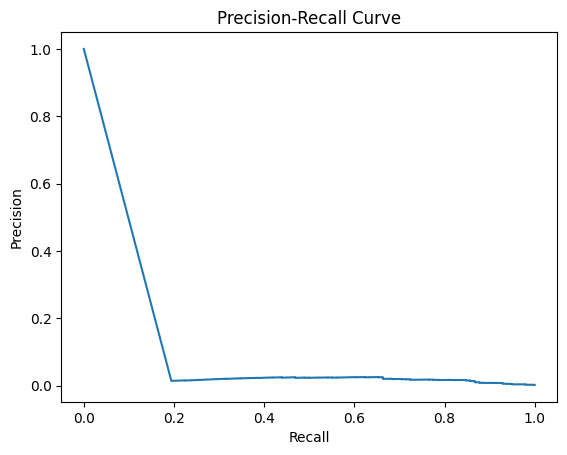

In [24]:
perform_experiment()

In [ ]:
from imblearn.combine import SMOTETomek

smote_tomek = SMOTETomek(random_state=42)
X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
print("Number of instances per class:")
print(y_resampled.value_counts())

In [ ]:
perform_experiment()

In [ ]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline([
    ('imb', SMOTETomek(random_state=42)),
    ('model', RandomForestClassifier(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X, y, cv=cv, scoring='roc_auc')
print(f"ROC AUC scores: {scores}")
print(f"Mean ROC AUC: {scores.mean()}")

